In [5]:
import pandas as pd

df = pd.read_csv('Text_classification.csv')
print(df.head())

  Category                                            Message
0      ham  Go until jurong point, crazy.. Available only ...
1      ham                      Ok lar... Joking wif u oni...
2     spam  Free entry in 2 a wkly comp to win FA Cup fina...
3      ham  U dun say so early hor... U c already then say...
4      ham  Nah I don't think he goes to usf, he lives aro...


penjelasan : 
1. import pandas as pd: Mengimpor library Pandas untuk mengolah data berbentuk tabel.
2. pd.read_csv(...): Membaca dataset dari file CSV dan menyimpannya ke variabel df.
3. print(df.head()): Menampilkan lima baris pertama dataset untuk melihat isi data pesan dan kategorinya.

In [17]:
%pip install nltk

Note: you may need to restart the kernel to use updated packages.


In [6]:
# Download resource NLTK yang diperlukan
import nltk
nltk.download('punkt_tab')
nltk.download( 'punkt')
nltk.download('stopwords')
nltk.download('wordnet')
# Import library untuk preprocessing
import re
import string
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
# Inisialisasi lemmatizer
lemmatizer = WordNetLemmatizer()
# Fungsi preprocessing teks
def clean_text(text):
    text = text. lower() # Ubah menjadi lowercase
    text = re. sub(r'\d+', '', text) # Hapus angka
    text = text. translate(str.maketrans('', '', string.punctuation)) # Hapus tanda baca
    words = word_tokenize(text) # Tokenisasi
    words = [word for word in words if word not in stopwords.words('english' )] # Hapus stopwords
    words = [lemmatizer.lemmatize(word) for word in words] # Lemmatization
    return ' '.join(words)

# Terapkan preprocessing ke teks
df['clean_text'] = df['Message'].apply(clean_text)

# Cek hasil preprocessing
print("\nHasil Preprocessing:\n", df[['Message', 'clean_text']].head())

[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\sthab\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\sthab\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\sthab\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\sthab\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!



Hasil Preprocessing:
                                              Message  \
0  Go until jurong point, crazy.. Available only ...   
1                      Ok lar... Joking wif u oni...   
2  Free entry in 2 a wkly comp to win FA Cup fina...   
3  U dun say so early hor... U c already then say...   
4  Nah I don't think he goes to usf, he lives aro...   

                                          clean_text  
0  go jurong point crazy available bugis n great ...  
1                            ok lar joking wif u oni  
2  free entry wkly comp win fa cup final tkts st ...  
3                u dun say early hor u c already say  
4           nah dont think go usf life around though  


penjelasan : 
1. nltk.download(...): Mengunduh resource yang dibutuhkan untuk pemrosesan teks.
2. import re dan import string: Menyediakan fungsi untuk menghapus angka dan tanda baca.
3. stopwords, word_tokenize, dan WordNetLemmatizer: Digunakan untuk menghapus kata umum, memisahkan kata, dan mengubah kata ke bentuk dasarnya.
4. lemmatizer = WordNetLemmatizer(): Membuat objek untuk melakukan lemmatization.
5. def clean_text(text): Membuat fungsi untuk membersihkan teks.
6. text.lower(): Mengubah huruf menjadi huruf kecil.
7. re.sub(r'\d+', '', text): Menghapus angka.
8. text.translate(...): Menghapus tanda baca.
9. word_tokenize(text): Memisahkan kalimat menjadi kata-kata.
10. stopwords.words('english'): Menghapus kata umum bahasa Inggris yang ada dalam daftar stopwords.
11. lemmatizer.lemmatize(word): Mengubah kata menjadi bentuk dasarnya.
12. .join(words): Menggabungkan kata-kata kembali menjadi kalimat.
13. df['Message'].apply(clean_text): Menerapkan preprocessing pada semua pesan dan menyimpan hasilnya ke kolom clean_text.
14. print(...): Menampilkan pesan asli dan hasil preprocessing.

In [7]:
# Ubah label dari 'ham'/'spam' menjadi 0/1
df['Category' ] = df['Category' ].map({'ham': 0, 'spam': 1})

# Cek jumlah masing-masing kelas
print(df['Category' ].value_counts())

Category
0    4825
1     747
Name: count, dtype: int64


penjelasan 
1. .map(...): mengubah kategori ham menjadi angka 0 dan spam menjadi angka 1.
2. value_counys(): Menghitung jumlah data pada setiap kategori
tujuannya agar label digunakan oleh model machine learning

In [9]:
from sklearn.model_selection import train_test_split
# Pisahkan fitur dan label
X = df['clean_text' ]
y = df['Category' ]

# Split data (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

penjelasan :
1. train_test_split: menimpor fungsi untuk membagi dataset
2. X = df['clean_text']: menentukan teks bersih sebagai fitur atau input
3. y = df['Category']: Menentukan kategori sebagai target prediksi
4. test_size=0.2: Menggunakan 80% data untuk training dan 20% untuk testing
5. random_state=42 : Mmebuat pembagian dat adapat diulang dengan pengaturan yang sama
6. stratify=y : menjaga proporsi kategori pada data training dan testing

In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Konversi teks menjadi fitur numerik menggunakan TF-IDF
vectorizer = TfidfVectorizer(ngram_range=(1,2), max_features=5000) # Menggunakan bigram
X_train_tfidf = vectorizer. fit_transform(X_train)
X_test_tfidf = vectorizer. transform(X_test)

print("\nTF-IDF Shape (Train):", X_train_tfidf.shape)


TF-IDF Shape (Train): (4457, 5000)


penjelasan :
1. TfidfVectorizer: Mengubah teks menjadi angka berdasarkan bobot kata.
2. ngram_range=(1, 2): Menggunakan kombinasi satu kata dan dua kata berurutan.
3. max_features=5000: Membatasi jumlah fitur maksimal sebanyak 5.000.
4. fit_transform(X_train): Mempelajari kosakata dari data training dan mengubahnya menjadi fitur numerik.
5. transform(X_test): Mengubah data testing menggunakan kosakata yang sudah dipelajari.
6. shape: Menampilkan jumlah baris data dan jumlah fitur.

In [11]:
from sklearn.naive_bayes import MultinomialNB

# Inisialisasi model Naïve Bayes
model = MultinomialNB(alpha=0.1)

# Train model
model.fit(X_train_tfidf, y_train)

# Prediksi hasil
y_pred = model.predict(X_test_tfidf)

penjelasan :
1. MultinomialNB: Mengimpor algoritma Naïve Bayes untuk klasifikasi.
2. MultinomialNB(alpha=0.1): Membuat model dengan parameter smoothing sebesar 0,1.
3. model.fit( ... ): Melatih model menggunakan data training.
4. model.predict( ... ): Menghasilkan prediksi kategori untuk data testing.
5. y_pred: Menyimpan hasil prediksi model.

In [12]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Akurasi
accuracy = accuracy_score(y_test, y_pred)
print("\nAccuracy:", accuracy)

# Classification Report
print("\nClassification Report:\n", classification_report(y_test, y_pred))


Accuracy: 0.979372197309417

Classification Report:
               precision    recall  f1-score   support

           0       0.98      1.00      0.99       966
           1       0.98      0.86      0.92       149

    accuracy                           0.98      1115
   macro avg       0.98      0.93      0.95      1115
weighted avg       0.98      0.98      0.98      1115



In [ ]:
penjelasan : 
1. accuracy_score: Mengimpor fungsi untuk menghitung akurasi.
2. classification_report: Mengimpor fungsi untuk menampilkan metrik evaluasi.
3. confusion_matrix: Mengimpor fungsi untuk membuat confusion matrix.
4. accuracy_score(y_test, y_pred): Menghitung persentase prediksi yang benar.
5. classification_report( ... ): Menampilkan precision, recall, F1-score, dan support.

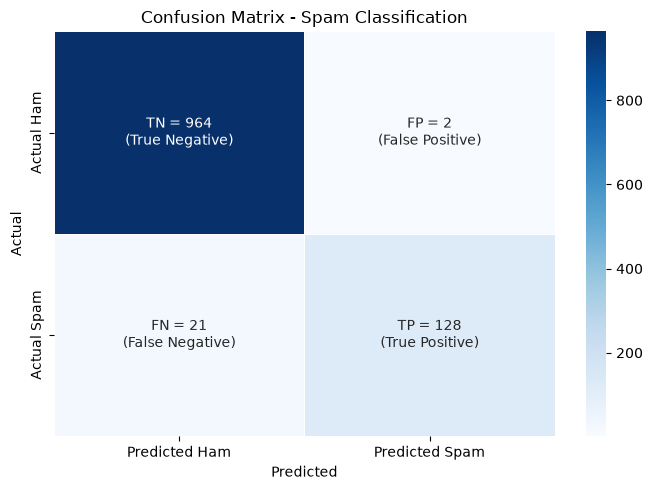

In [14]:
# Confusion Matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

# Hitung confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)

# Definisi elemen dalam confusion matrix
TN, FP, FN, TP = conf_matrix.ravel()

# Buat DataFrame confusion matrix
df_conf_matrix = pd.DataFrame (
    conf_matrix,
    index=['Actual Ham', 'Actual Spam'],
    columns=['Predicted Ham', 'Predicted Spam']
)

# Label untuk TN, FP, FN, TP
labels = np. array([
    [f"TN = {TN}\n(True Negative)", f"FP = {FP}\n(False Positive)"],
    [f"FN = {FN}\n(False Negative)", f"TP = {TP}\n(True Positive)"]
])

# Plot heatmap dengan keterangan
plt.figure(figsize=(7, 5))
ax = sns.heatmap(
    df_conf_matrix,
    annot=labels,
    fmt='',
    cmap='Blues',
    linewidths=0.5,
    cbar=True
)

# Tambahkan label dan judul
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Spam Classification')

plt.tight_layout()
plt.show()

In [ ]:
penjelasan : 
1. seaborn,matplotlib,dan numpy: Digunakan untuk membuat visualisasi dan mengatur label.
2. confusion_matrix(y_test, y_pred): Membandingkan kategori sebenarnya dengan hasil prediksi.
3. conf_matrix.ravel(): Mengambil empat nilai, yaitu TN, FP, FN, dan TP.
4. pd.DataFrame( ... ): Mengubah matriks menjadi tabel dengan label baris dan kolom.
5. np.array(): Membuat keterangan untuk setiap nilai confusion matrix.
6. plt.figure(): Mengatur ukuran grafik.
7. sns.heatmap(): Membuat grafik berbentuk peta warna.
8. annot=labels: Menampilkan nilai dan keterangan pada setiap sel.
9. cmap='Blues': Menggunakan gradasi warna biru.
10. plt.xlabel() dan plt.ylabel(): Memberi nama sumbu.
11. plt.title0: Memberi judul grafik.
12. plt.show(): Menampilkan grafik.

In [16]:
#Contoh teks baru
new_texts = ["Congratulations! You won a free trip to Bali.",
"Hey, are you coming to the party tonight?"]

# Preprocess teks baru
new_texts_clean = [clean_text(text) for text in new_texts]

# Transformasi dengan TF-IDF
new_texts_tfidf = vectorizer. transform(new_texts_clean)

# Prediksi
predictions = model.predict(new_texts_tfidf)

# Output hasil prediksi
for text, label in zip(new_texts, predictions):
    print(f"\nMessage: {text} \nPredicted: {'Spam' if label == 1 else 'Ham'}")


Message: Congratulations! You won a free trip to Bali. 
Predicted: Spam

Message: Hey, are you coming to the party tonight? 
Predicted: Ham


In [ ]:
penjelasan : 
1. new_texts: Menyimpan dua contoh pesan baru yang akan diuji.
2. clean_text(text): Membersihkan setiap pesan sebelum diprediksi.
3. vectorizer.transform( ... ): Mengubah pesan menjadi fitur TF-IDF menggunakan kosakata dari proses training.
4. model.predict( ... ): Memprediksi kategori pesan.
5. zip(new_texts, predictions): Memasangkan setiap pesan dengan hasil prediksinya.
6. label == 1: Menampilkan kategori Spam.
7. label == 0: Menampilkan kategori Ham.
8. print( ... ): Menampilkan pesan beserta hasil klasifikasinya.